In [ ]:
# ================================================================
# PHASE 1A — CELL 1
# MOUNT GOOGLE DRIVE
# ================================================================

from google.colab import drive

drive.mount("/content/drive")

print("✓ Google Drive mounted.")

Mounted at /content/drive
✓ Google Drive mounted.


In [ ]:
# ================================================================
# PHASE 1A — CELL 2
# INSTALL DEPENDENCIES
# ================================================================

!pip -q install nibabel

In [ ]:
# ================================================================
# PHASE 1A — CELL 3
# IMPORTS + REPRODUCIBILITY
# ================================================================

import os
import gc
import json
import time
import random
import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import nibabel as nib
import tensorflow as tf

import matplotlib.pyplot as plt

from scipy.ndimage import binary_fill_holes
from scipy.spatial.distance import cdist

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Seed:", SEED)

TensorFlow: 2.20.0
Seed: 42


In [ ]:
# ================================================================
# PHASE 1A — CELL 4
# NEW PROJECT STRUCTURE
# ================================================================

PROJECT_DIR = Path(
    "/content/drive/MyDrive/CAMUS_FINAL"
)

CONFIG_DIR = PROJECT_DIR / "configs"
SPLIT_DIR = PROJECT_DIR / "splits"

PHASE1_DIR = PROJECT_DIR / "phase1_segmentation"

PHASE1A_DIR = PHASE1_DIR / "phase1A_resolution"
PHASE1B_DIR = PHASE1_DIR / "phase1B_hyperparameters"
PHASE1C_DIR = PHASE1_DIR / "phase1C_capacity"
PHASE1D_DIR = PHASE1_DIR / "phase1D_loss"
PHASE1E_DIR = PHASE1_DIR / "phase1E_final_validation"
PHASE1F_DIR = PHASE1_DIR / "phase1F_final_model"

PHASE2_DIR = PROJECT_DIR / "phase2_quantitative"

for folder in [
    CONFIG_DIR,
    SPLIT_DIR,
    PHASE1A_DIR,
    PHASE1B_DIR,
    PHASE1C_DIR,
    PHASE1D_DIR,
    PHASE1E_DIR,
    PHASE1F_DIR,
    PHASE2_DIR,
]:
    folder.mkdir(
        parents=True,
        exist_ok=True
    )

# Phase 1A subfolders
P1A_MODEL_DIR = PHASE1A_DIR / "models"
P1A_HISTORY_DIR = PHASE1A_DIR / "histories"
P1A_TABLE_DIR = PHASE1A_DIR / "tables"
P1A_PLOT_DIR = PHASE1A_DIR / "plots"
P1A_CONFIG_DIR = PHASE1A_DIR / "configs"

for folder in [
    P1A_MODEL_DIR,
    P1A_HISTORY_DIR,
    P1A_TABLE_DIR,
    P1A_PLOT_DIR,
    P1A_CONFIG_DIR,
]:
    folder.mkdir(
        parents=True,
        exist_ok=True
    )

print("New project:")
print(PROJECT_DIR)

print("\n✓ Clean project structure created.")

New project:
/content/drive/MyDrive/CAMUS_FINAL

✓ Clean project structure created.


In [ ]:
# ================================================================
# PHASE 1A — CELL 5
# CAMUS DATASET PATHS
# ================================================================

OUTER_ZIP_PATH = Path(
    "/content/drive/MyDrive/download.zip"
)

OUTER_EXTRACT_DIR = Path(
    "/content/camus_data"
)

INNER_ARCHIVE_PATH = (
    OUTER_EXTRACT_DIR / "download"
)

INNER_EXTRACT_DIR = Path(
    "/content/camus_data_final"
)

assert OUTER_ZIP_PATH.exists(), (
    f"Outer archive not found:\n{OUTER_ZIP_PATH}"
)

print("Outer archive:")
print(OUTER_ZIP_PATH)

print("\n✓ CAMUS archive found.")

Outer archive:
/content/drive/MyDrive/download.zip

✓ CAMUS archive found.


In [ ]:
# ================================================================
# PHASE 1A — CELL 6
# TWO-STAGE CAMUS EXTRACTION
# ================================================================

# ------------------------------------------------
# Stage 1
# ------------------------------------------------

OUTER_EXTRACT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

if not INNER_ARCHIVE_PATH.exists():

    print("Extracting outer archive...")

    with zipfile.ZipFile(
        OUTER_ZIP_PATH,
        "r"
    ) as z:

        z.extractall(
            OUTER_EXTRACT_DIR
        )

    print("✓ Outer archive extracted.")

else:

    print("✓ Outer archive already extracted.")


# ------------------------------------------------
# Locate inner archive
# ------------------------------------------------

possible_inner = [
    OUTER_EXTRACT_DIR / "download",
    OUTER_EXTRACT_DIR / "download.zip",
]

inner_archive = None

for candidate in possible_inner:

    if candidate.exists():
        inner_archive = candidate
        break

if inner_archive is None:

    raise FileNotFoundError(
        "Inner CAMUS archive was not found."
    )

print("\nInner archive:")
print(inner_archive)


# ------------------------------------------------
# Stage 2
# ------------------------------------------------

INNER_EXTRACT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

existing_database = list(
    INNER_EXTRACT_DIR.rglob(
        "database_nifti"
    )
)

if len(existing_database) == 0:

    print("\nExtracting inner archive...")

    with zipfile.ZipFile(
        inner_archive,
        "r"
    ) as z:

        z.extractall(
            INNER_EXTRACT_DIR
        )

    print("✓ Inner archive extracted.")

else:

    print(
        "✓ Inner archive already extracted."
    )


# ------------------------------------------------
# Locate database_nifti
# ------------------------------------------------

database_candidates = list(
    INNER_EXTRACT_DIR.rglob(
        "database_nifti"
    )
)

if len(database_candidates) != 1:

    print(
        "database_nifti candidates:",
        database_candidates
    )

    raise RuntimeError(
        "Could not uniquely locate database_nifti."
    )

DATASET_PATH = database_candidates[0]

print("\nCAMUS dataset:")
print(DATASET_PATH)

Extracting outer archive...
✓ Outer archive extracted.

Inner archive:
/content/camus_data/download

Extracting inner archive...
✓ Inner archive extracted.

CAMUS dataset:
/content/camus_data_final/database_nifti


In [ ]:
# ================================================================
# PHASE 1A — CELL 7
# DATASET INTEGRITY CHECK
# ================================================================

patient_dirs = sorted([
    p
    for p in DATASET_PATH.iterdir()
    if (
        p.is_dir()
        and p.name.startswith("patient")
    )
])

patient_ids = [
    p.name
    for p in patient_dirs
]

print("Patients found:", len(patient_ids))

assert len(patient_ids) == 500, (
    f"Expected 500 patients, found {len(patient_ids)}"
)

print("First 5:")
print(patient_ids[:5])

print("\nLast 5:")
print(patient_ids[-5:])

print("\n✓ Exactly 500 CAMUS patients verified.")

Patients found: 500
First 5:
['patient0001', 'patient0002', 'patient0003', 'patient0004', 'patient0005']

Last 5:
['patient0496', 'patient0497', 'patient0498', 'patient0499', 'patient0500']

✓ Exactly 500 CAMUS patients verified.


In [ ]:
# ================================================================
# PHASE 1A — CELL 8
# VERIFY A4C ED/ES IMAGE-MASK PAIRS
# ================================================================

missing_records = []

for pid in patient_ids:

    pdir = DATASET_PATH / pid

    required_files = [
        pdir / f"{pid}_4CH_ED.nii.gz",
        pdir / f"{pid}_4CH_ED_gt.nii.gz",
        pdir / f"{pid}_4CH_ES.nii.gz",
        pdir / f"{pid}_4CH_ES_gt.nii.gz",
    ]

    missing = [
        str(path.name)
        for path in required_files
        if not path.exists()
    ]

    if missing:

        missing_records.append({
            "patient_id": pid,
            "missing_files": missing
        })


print(
    "Patients with missing files:",
    len(missing_records)
)

assert len(missing_records) == 0, (
    "Some patients are missing required A4C files."
)

print("✓ All 500 patients contain ED/ES A4C image-mask pairs.")
print("✓ Total usable frames:", 500 * 2)

Patients with missing files: 0
✓ All 500 patients contain ED/ES A4C image-mask pairs.
✓ Total usable frames: 1000


In [ ]:
# ================================================================
# PHASE 1A — CELL 9
# RAW DATA INSPECTION
# ================================================================

sample_pid = patient_ids[0]

sample_dir = (
    DATASET_PATH / sample_pid
)

for phase in ["ED", "ES"]:

    image_path = (
        sample_dir
        / f"{sample_pid}_4CH_{phase}.nii.gz"
    )

    mask_path = (
        sample_dir
        / f"{sample_pid}_4CH_{phase}_gt.nii.gz"
    )

    image_nii = nib.load(
        str(image_path)
    )

    mask_nii = nib.load(
        str(mask_path)
    )

    image = np.asarray(
        image_nii.get_fdata()
    ).squeeze()

    mask = np.asarray(
        mask_nii.get_fdata()
    ).squeeze()

    print("\n", phase)

    print(
        "Image shape:",
        image.shape
    )

    print(
        "Mask shape:",
        mask.shape
    )

    print(
        "Image range:",
        float(image.min()),
        float(image.max())
    )

    print(
        "Mask labels:",
        np.unique(mask)
    )

    print(
        "Pixel spacing:",
        image_nii.header.get_zooms()[:2]
    )


 ED
Image shape: (549, 389)
Mask shape: (549, 389)
Image range: 0.0 255.0
Mask labels: [0. 1. 2. 3.]
Pixel spacing: (np.float32(0.308), np.float32(0.308))

 ES
Image shape: (549, 389)
Mask shape: (549, 389)
Image range: 0.0 255.0
Mask labels: [0. 1. 2. 3.]
Pixel spacing: (np.float32(0.308), np.float32(0.308))


In [ ]:
# ================================================================
# PHASE 1A — CELL 10
# CREATE PATIENT-LEVEL SPLIT
# ================================================================

SPLIT_JSON_PATH = (
    SPLIT_DIR
    / "patient_split_seed42.json"
)

SPLIT_CSV_PATH = (
    SPLIT_DIR
    / "patient_split_seed42.csv"
)


if SPLIT_JSON_PATH.exists():

    print("Existing clean split found.")

    with open(
        SPLIT_JSON_PATH,
        "r"
    ) as f:

        split_data = json.load(f)

    train_ids = split_data["train"]
    val_ids = split_data["validation"]
    test_ids = split_data["test"]

else:

    shuffled_ids = sorted(
        patient_ids
    )

    rng = random.Random(SEED)

    rng.shuffle(
        shuffled_ids
    )

    train_ids = shuffled_ids[:400]

    val_ids = shuffled_ids[400:450]

    test_ids = shuffled_ids[450:500]

    split_data = {
        "seed": SEED,
        "method": (
            "patient-level random split "
            "after sorting patient IDs"
        ),
        "train": train_ids,
        "validation": val_ids,
        "test": test_ids,
    }

    with open(
        SPLIT_JSON_PATH,
        "w"
    ) as f:

        json.dump(
            split_data,
            f,
            indent=2
        )

    rows = []

    for split_name, ids in [
        ("train", train_ids),
        ("validation", val_ids),
        ("test", test_ids),
    ]:

        for pid in ids:

            rows.append({
                "patient_id": pid,
                "split": split_name
            })

    pd.DataFrame(
        rows
    ).to_csv(
        SPLIT_CSV_PATH,
        index=False
    )

    print("✓ New split created and saved.")


print("\nTrain patients:", len(train_ids))
print("Validation patients:", len(val_ids))
print("Test patients:", len(test_ids))

print("\nTraining frames:", len(train_ids) * 2)
print("Validation frames:", len(val_ids) * 2)
print("Test frames:", len(test_ids) * 2)

✓ New split created and saved.

Train patients: 400
Validation patients: 50
Test patients: 50

Training frames: 800
Validation frames: 100
Test frames: 100


In [ ]:
# ================================================================
# PHASE 1A — CELL 11
# VERIFY PATIENT-LEVEL SPLIT
# ================================================================

train_set = set(train_ids)
val_set = set(val_ids)
test_set = set(test_ids)

assert train_set.isdisjoint(
    val_set
)

assert train_set.isdisjoint(
    test_set
)

assert val_set.isdisjoint(
    test_set
)

assert (
    len(
        train_set
        | val_set
        | test_set
    )
    == 500
)

print("✓ No patient overlap.")
print("✓ All 500 patients accounted for.")

✓ No patient overlap.
✓ All 500 patients accounted for.


In [ ]:
# ================================================================
# PHASE 1A — CELL 12
# SAVE EXPERIMENTAL PROTOCOL
# ================================================================

phase1a_protocol = {

    "experiment_name":
        "Phase1A_Controlled_Resolution",

    "research_question":
        (
            "How does input resolution affect "
            "A4C LV cavity segmentation when "
            "architecture and training conditions "
            "are kept fixed?"
        ),

    "dataset":
        "CAMUS",

    "view":
        "A4C",

    "target":
        "LV cavity (CAMUS label 1)",

    "patients":
        500,

    "split": {
        "train": 400,
        "validation": 50,
        "test": 50,
        "seed": SEED
    },

    "resolutions": [
        128,
        256,
        512
    ],

    "controlled_variables": [
        "architecture",
        "optimizer",
        "learning_rate",
        "loss",
        "batch_size",
        "augmentation",
        "patient_split",
        "random_seed",
        "training policy"
    ],

    "selection_data":
        "validation only",

    "test_policy":
        (
            "Do not use the test set for "
            "resolution selection."
        )
}


with open(
    P1A_CONFIG_DIR
    / "phase1A_protocol.json",
    "w"
) as f:

    json.dump(
        phase1a_protocol,
        f,
        indent=2
    )


print(
    json.dumps(
        phase1a_protocol,
        indent=2
    )
)

{
  "experiment_name": "Phase1A_Controlled_Resolution",
  "research_question": "How does input resolution affect A4C LV cavity segmentation when architecture and training conditions are kept fixed?",
  "dataset": "CAMUS",
  "view": "A4C",
  "target": "LV cavity (CAMUS label 1)",
  "patients": 500,
  "split": {
    "train": 400,
    "validation": 50,
    "test": 50,
    "seed": 42
  },
  "resolutions": [
    128,
    256,
    512
  ],
  "controlled_variables": [
    "architecture",
    "optimizer",
    "learning_rate",
    "loss",
    "batch_size",
    "augmentation",
    "patient_split",
    "random_seed",
    "training policy"
  ],
  "selection_data": "validation only",
  "test_policy": "Do not use the test set for resolution selection."
}


In [ ]:
# ================================================================
# PHASE 1A — CELL 13
# MEMORY-SAFE CAMUS LOADER
# ================================================================

def load_nifti_2d(path):

    nii = nib.load(
        str(path)
    )

    data = np.asarray(
        nii.get_fdata()
    )

    data = np.squeeze(
        data
    )

    if data.ndim != 2:

        raise ValueError(
            f"Expected 2D image, got "
            f"{data.shape}: {path}"
        )

    return data


def load_camus_frame(
    patient_id,
    phase
):

    pdir = (
        DATASET_PATH
        / patient_id
    )

    image = load_nifti_2d(
        pdir
        / f"{patient_id}_4CH_{phase}.nii.gz"
    )

    gt = load_nifti_2d(
        pdir
        / f"{patient_id}_4CH_{phase}_gt.nii.gz"
    )

    image = image.astype(
        np.float32
    )

    # Label 1 = LV cavity
    lv_mask = (
        gt == 1
    ).astype(
        np.float32
    )

    return image, lv_mask


print("✓ Loader ready.")

✓ Loader ready.


In [ ]:
# ================================================================
# PHASE 1A — CELL 14
# CONTROLLED PREPROCESSING
# ================================================================

def preprocess_frame(
    image,
    mask,
    resolution
):

    image = cv2.resize(
        image,
        (resolution, resolution),
        interpolation=cv2.INTER_LINEAR
    )

    mask = cv2.resize(
        mask.astype(np.uint8),
        (resolution, resolution),
        interpolation=cv2.INTER_NEAREST
    )

    image = image.astype(
        np.float32
    )

    lo = float(
        image.min()
    )

    hi = float(
        image.max()
    )

    if hi > lo:

        image = (
            image - lo
        ) / (
            hi - lo
        )

    else:

        image = np.zeros_like(
            image,
            dtype=np.float32
        )

    mask = (
        mask > 0
    ).astype(
        np.float32
    )

    return (
        image[..., None],
        mask[..., None]
    )

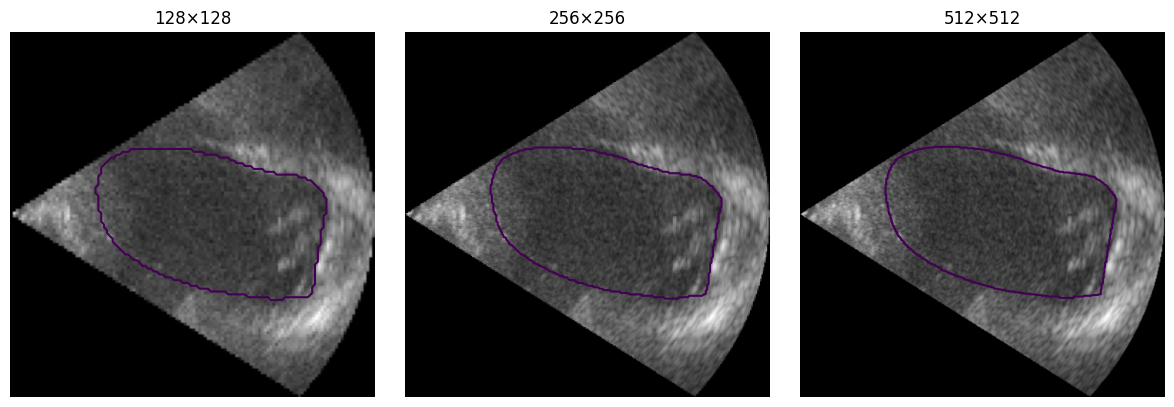

71

In [ ]:
# ================================================================
# PHASE 1A — CELL 15
# PREPROCESSING SANITY CHECK
# ================================================================

sample_image, sample_mask = (
    load_camus_frame(
        train_ids[0],
        "ED"
    )
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(12, 4)
)

for ax, resolution in zip(
    axes,
    [128, 256, 512]
):

    x, y = preprocess_frame(
        sample_image,
        sample_mask,
        resolution
    )

    ax.imshow(
        x[:, :, 0],
        cmap="gray"
    )

    ax.contour(
        y[:, :, 0],
        levels=[0.5]
    )

    ax.set_title(
        f"{resolution}×{resolution}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

del sample_image
del sample_mask

gc.collect()

In [ ]:
# ================================================================
# PHASE 1A — CELL 16
# DISK-BASED KERAS SEQUENCE
# ================================================================

class CAMUSSequence(
    tf.keras.utils.Sequence
):

    def __init__(
        self,
        patient_ids,
        resolution,
        batch_size=4,
        shuffle=False,
        seed=42,
        **kwargs
    ):

        super().__init__(**kwargs)

        self.patient_ids = list(
            patient_ids
        )

        self.resolution = int(
            resolution
        )

        self.batch_size = int(
            batch_size
        )

        self.shuffle = shuffle

        self.rng = np.random.default_rng(
            seed
        )

        self.samples = []

        for pid in self.patient_ids:

            self.samples.append(
                (pid, "ED")
            )

            self.samples.append(
                (pid, "ES")
            )

        self.indices = np.arange(
            len(self.samples)
        )

        self.on_epoch_end()


    def __len__(self):

        return int(
            np.ceil(
                len(self.samples)
                / self.batch_size
            )
        )


    def __getitem__(
        self,
        batch_index
    ):

        start = (
            batch_index
            * self.batch_size
        )

        end = min(
            start + self.batch_size,
            len(self.samples)
        )

        batch_indices = (
            self.indices[start:end]
        )

        current_batch_size = len(
            batch_indices
        )

        X = np.empty(
            (
                current_batch_size,
                self.resolution,
                self.resolution,
                1
            ),
            dtype=np.float32
        )

        Y = np.empty_like(
            X
        )

        for j, idx in enumerate(
            batch_indices
        ):

            pid, phase = (
                self.samples[idx]
            )

            image, mask = (
                load_camus_frame(
                    pid,
                    phase
                )
            )

            image, mask = (
                preprocess_frame(
                    image,
                    mask,
                    self.resolution
                )
            )

            X[j] = image
            Y[j] = mask

        return X, Y


    def on_epoch_end(self):

        if self.shuffle:

            self.rng.shuffle(
                self.indices
            )

In [ ]:
# ================================================================
# PHASE 1A — CELL 17
# GENERATOR CHECK
# ================================================================

for resolution in [
    128,
    256,
    512
]:

    temp_gen = CAMUSSequence(
        train_ids[:4],
        resolution=resolution,
        batch_size=2,
        shuffle=False,
        seed=SEED
    )

    X, Y = temp_gen[0]

    print(
        f"\n{resolution}×{resolution}"
    )

    print(
        "X:",
        X.shape,
        X.dtype,
        X.min(),
        X.max()
    )

    print(
        "Y:",
        Y.shape,
        Y.dtype,
        np.unique(Y)
    )

    del temp_gen
    del X
    del Y

    gc.collect()


128×128
X: (2, 128, 128, 1) float32 0.0 1.0
Y: (2, 128, 128, 1) float32 [0. 1.]

256×256
X: (2, 256, 256, 1) float32 0.0 1.0
Y: (2, 256, 256, 1) float32 [0. 1.]

512×512
X: (2, 512, 512, 1) float32 0.0 1.0
Y: (2, 512, 512, 1) float32 [0. 1.]


In [ ]:
# ================================================================
# PHASE 1A — CELL 18
# LOSS + METRICS
# ================================================================

EPS = 1e-6


def dice_coefficient(
    y_true,
    y_pred
):

    y_true = tf.cast(
        y_true,
        tf.float32
    )

    y_pred = tf.cast(
        y_pred,
        tf.float32
    )

    intersection = tf.reduce_sum(
        y_true * y_pred,
        axis=[1, 2, 3]
    )

    denominator = (
        tf.reduce_sum(
            y_true,
            axis=[1, 2, 3]
        )
        +
        tf.reduce_sum(
            y_pred,
            axis=[1, 2, 3]
        )
    )

    dice = (
        2.0 * intersection
        + EPS
    ) / (
        denominator
        + EPS
    )

    return tf.reduce_mean(
        dice
    )


def iou_metric(
    y_true,
    y_pred
):

    y_true = tf.cast(
        y_true,
        tf.float32
    )

    y_pred = tf.cast(
        y_pred,
        tf.float32
    )

    intersection = tf.reduce_sum(
        y_true * y_pred,
        axis=[1, 2, 3]
    )

    union = (
        tf.reduce_sum(
            y_true,
            axis=[1, 2, 3]
        )
        +
        tf.reduce_sum(
            y_pred,
            axis=[1, 2, 3]
        )
        -
        intersection
    )

    iou = (
        intersection + EPS
    ) / (
        union + EPS
    )

    return tf.reduce_mean(
        iou
    )


def dice_loss(
    y_true,
    y_pred
):

    return (
        1.0
        -
        dice_coefficient(
            y_true,
            y_pred
        )
    )


bce = tf.keras.losses.BinaryCrossentropy()


def bce_dice_loss(
    y_true,
    y_pred
):

    return (
        bce(
            y_true,
            y_pred
        )
        +
        dice_loss(
            y_true,
            y_pred
        )
    )


print("✓ BCE + Dice defined.")

✓ BCE + Dice defined.


In [ ]:
# ================================================================
# PHASE 1A — CELL 19
# FIXED BASELINE U-NET
# ================================================================

def conv_block(
    x,
    filters
):

    x = tf.keras.layers.Conv2D(
        filters,
        3,
        padding="same",
        activation="relu",
        kernel_initializer="he_normal"
    )(x)

    x = tf.keras.layers.Conv2D(
        filters,
        3,
        padding="same",
        activation="relu",
        kernel_initializer="he_normal"
    )(x)

    return x


def build_baseline_unet(
    resolution
):

    inputs = tf.keras.Input(
        shape=(
            resolution,
            resolution,
            1
        )
    )

    # Encoder
    c1 = conv_block(
        inputs,
        16
    )

    p1 = tf.keras.layers.MaxPooling2D(
        (2, 2)
    )(c1)


    c2 = conv_block(
        p1,
        32
    )

    p2 = tf.keras.layers.MaxPooling2D(
        (2, 2)
    )(c2)


    c3 = conv_block(
        p2,
        64
    )

    p3 = tf.keras.layers.MaxPooling2D(
        (2, 2)
    )(c3)


    c4 = conv_block(
        p3,
        128
    )

    p4 = tf.keras.layers.MaxPooling2D(
        (2, 2)
    )(c4)


    # Bottleneck
    c5 = conv_block(
        p4,
        256
    )


    # Decoder
    u6 = tf.keras.layers.Conv2DTranspose(
        128,
        2,
        strides=2,
        padding="same"
    )(c5)

    u6 = tf.keras.layers.Concatenate()(
        [u6, c4]
    )

    c6 = conv_block(
        u6,
        128
    )


    u7 = tf.keras.layers.Conv2DTranspose(
        64,
        2,
        strides=2,
        padding="same"
    )(c6)

    u7 = tf.keras.layers.Concatenate()(
        [u7, c3]
    )

    c7 = conv_block(
        u7,
        64
    )


    u8 = tf.keras.layers.Conv2DTranspose(
        32,
        2,
        strides=2,
        padding="same"
    )(c7)

    u8 = tf.keras.layers.Concatenate()(
        [u8, c2]
    )

    c8 = conv_block(
        u8,
        32
    )


    u9 = tf.keras.layers.Conv2DTranspose(
        16,
        2,
        strides=2,
        padding="same"
    )(c8)

    u9 = tf.keras.layers.Concatenate()(
        [u9, c1]
    )

    c9 = conv_block(
        u9,
        16
    )


    outputs = tf.keras.layers.Conv2D(
        1,
        1,
        activation="sigmoid"
    )(c9)


    return tf.keras.Model(
        inputs,
        outputs,
        name="Baseline_UNet"
    )

In [ ]:
# ================================================================
# PHASE 1A — CELL 20
# VERIFY ARCHITECTURE
# ================================================================

tf.keras.backend.clear_session()

architecture_check = (
    build_baseline_unet(
        256
    )
)

BASELINE_PARAMETER_COUNT = (
    architecture_check.count_params()
)

print(
    "Baseline U-Net parameters:",
    f"{BASELINE_PARAMETER_COUNT:,}"
)

architecture_check.summary()

del architecture_check

tf.keras.backend.clear_session()
gc.collect()

Baseline U-Net parameters: 1,940,817


Model: "Baseline_UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │        160 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │      2,320 │ conv2d[0][0]      │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │      4,640 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │      9,248 │ conv2d_2[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     18,496 │ max_pooling2d_1[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 64, 64,    │     36,928 │ conv2d_4[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 32, 32,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 32, 32,    │     73,856 │ max_pooling2d_2[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 32, 32,    │    147,584 │ conv2d_6[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 16, 16,    │          0 │ conv2d_7[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 16, 16,    │    295,168 │ max_pooling2d_3[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 16, 16,    │    590,080 │ conv2d_8[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 32, 32,    │    131,200 │ conv2d_9[0][0]    │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 32, 32,    │          0 │ conv2d_transpose

 Total params: 1,940,817 (7.40 MB)

 Trainable params: 1,940,817 (7.40 MB)

 Non-trainable params: 0 (0.00 B)

0

In [ ]:
# ================================================================
# PHASE 1A — CELL 21
# FIXED TRAINING CONFIGURATION
# ================================================================

PHASE1A_TRAINING_CONFIG = {

    "architecture": "Baseline_UNet",
    "filters": [16, 32, 64, 128, 256],

    "parameter_count": int(
        BASELINE_PARAMETER_COUNT
    ),

    "resolutions": [128, 256, 512],

    "optimizer": "Adam",
    "initial_learning_rate": 1e-4,

    "loss": "BCE + Dice",

    "batch_size": 4,
    "epochs": 30,

    "augmentation": False,

    "threshold": 0.50,

    "checkpoint_monitor": "val_dice_coefficient",
    "checkpoint_mode": "max",

    "early_stopping": False,
    "reduce_lr_on_plateau": False,

    "seed": SEED,

    "train_patients": len(train_ids),
    "validation_patients": len(val_ids),

    "train_frames": len(train_ids) * 2,
    "validation_frames": len(val_ids) * 2,

    "test_used_for_selection": False
}


CONFIG_PATH = (
    P1A_CONFIG_DIR
    / "phase1A_training_config.json"
)


with open(
    CONFIG_PATH,
    "w"
) as f:

    json.dump(
        PHASE1A_TRAINING_CONFIG,
        f,
        indent=2
    )


print(
    json.dumps(
        PHASE1A_TRAINING_CONFIG,
        indent=2
    )
)

print("\n✓ Phase 1A configuration frozen.")

{
  "architecture": "Baseline_UNet",
  "filters": [
    16,
    32,
    64,
    128,
    256
  ],
  "parameter_count": 1940817,
  "resolutions": [
    128,
    256,
    512
  ],
  "optimizer": "Adam",
  "initial_learning_rate": 0.0001,
  "loss": "BCE + Dice",
  "batch_size": 4,
  "epochs": 30,
  "augmentation": false,
  "threshold": 0.5,
  "checkpoint_monitor": "val_dice_coefficient",
  "checkpoint_mode": "max",
  "early_stopping": false,
  "reduce_lr_on_plateau": false,
  "seed": 42,
  "train_patients": 400,
  "validation_patients": 50,
  "train_frames": 800,
  "validation_frames": 100,
  "test_used_for_selection": false
}

✓ Phase 1A configuration frozen.


In [ ]:
# ================================================================
# PHASE 1A — CELL 22
# GPU CHECK
# ================================================================

gpus = tf.config.list_physical_devices(
    "GPU"
)

print("GPUs detected:", gpus)

if not gpus:
    raise RuntimeError(
        "No GPU detected. "
        "In Colab select Runtime → Change runtime type → GPU."
    )

print("\n✓ GPU available.")

GPUs detected: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

✓ GPU available.


In [ ]:
# ================================================================
# PHASE 1A — CELL 23
# CONTROLLED TRAINING FUNCTION
# ================================================================

def train_resolution_experiment(
    resolution
):

    print("\n" + "=" * 70)
    print(
        f"TRAINING {resolution}×{resolution}"
    )
    print("=" * 70)

    # ------------------------------------------------------------
    # Clean previous TensorFlow state
    # ------------------------------------------------------------

    tf.keras.backend.clear_session()
    gc.collect()

    random.seed(SEED)
    np.random.seed(SEED)
    tf.random.set_seed(SEED)


    # ------------------------------------------------------------
    # Generators
    # ------------------------------------------------------------

    train_gen = CAMUSSequence(
        train_ids,
        resolution=resolution,
        batch_size=4,
        shuffle=True,
        seed=SEED
    )

    val_gen = CAMUSSequence(
        val_ids,
        resolution=resolution,
        batch_size=4,
        shuffle=False,
        seed=SEED
    )


    # ------------------------------------------------------------
    # Model
    # ------------------------------------------------------------

    segmentation_model = (
        build_baseline_unet(
            resolution
        )
    )

    assert (
        segmentation_model.count_params()
        == BASELINE_PARAMETER_COUNT
    )


    # ------------------------------------------------------------
    # Compile
    # ------------------------------------------------------------

    optimizer = tf.keras.optimizers.Adam(
        learning_rate=1e-4
    )

    segmentation_model.compile(

        optimizer=optimizer,

        loss=bce_dice_loss,

        metrics=[
            dice_coefficient,
            iou_metric
        ]
    )


    # ------------------------------------------------------------
    # Output paths
    # ------------------------------------------------------------

    model_path = (
        P1A_MODEL_DIR
        / f"baseline_unet_{resolution}.keras"
    )

    history_path = (
        P1A_HISTORY_DIR
        / f"history_{resolution}.csv"
    )


    # ------------------------------------------------------------
    # Save best validation-Dice checkpoint
    # ------------------------------------------------------------

    checkpoint = (
        tf.keras.callbacks.ModelCheckpoint(

            filepath=str(
                model_path
            ),

            monitor="val_dice_coefficient",

            mode="max",

            save_best_only=True,

            save_weights_only=False,

            verbose=1
        )
    )


    # ------------------------------------------------------------
    # Training
    # ------------------------------------------------------------

    start_time = time.time()

    history = segmentation_model.fit(

        train_gen,

        validation_data=val_gen,

        epochs=30,

        callbacks=[
            checkpoint
        ],

        verbose=1
    )

    elapsed_minutes = (
        time.time()
        - start_time
    ) / 60.0


    # ------------------------------------------------------------
    # Save complete history
    # ------------------------------------------------------------

    history_df = pd.DataFrame(
        history.history
    )

    history_df.insert(
        0,
        "epoch",
        np.arange(
            1,
            len(history_df) + 1
        )
    )

    history_df.to_csv(
        history_path,
        index=False
    )


    # ------------------------------------------------------------
    # Identify best epoch
    # ------------------------------------------------------------

    best_index = int(
        np.argmax(
            history.history[
                "val_dice_coefficient"
            ]
        )
    )

    best_epoch = (
        best_index + 1
    )

    best_val_dice = float(
        history.history[
            "val_dice_coefficient"
        ][best_index]
    )

    best_val_iou = float(
        history.history[
            "val_iou_metric"
        ][best_index]
    )


    training_summary = {

        "resolution": resolution,

        "parameters":
            int(BASELINE_PARAMETER_COUNT),

        "epochs_completed":
            len(history_df),

        "best_epoch":
            best_epoch,

        "best_val_dice_training":
            best_val_dice,

        "val_iou_at_best_dice_epoch":
            best_val_iou,

        "training_minutes":
            float(elapsed_minutes),

        "model_path":
            str(model_path),

        "history_path":
            str(history_path)
    }


    summary_path = (
        P1A_TABLE_DIR
        / f"training_summary_{resolution}.json"
    )

    with open(
        summary_path,
        "w"
    ) as f:

        json.dump(
            training_summary,
            f,
            indent=2
        )


    print("\n" + "-" * 70)

    print(
        f"{resolution}×{resolution} COMPLETE"
    )

    print(
        "Best epoch:",
        best_epoch
    )

    print(
        "Best validation Dice:",
        round(
            best_val_dice,
            6
        )
    )

    print(
        "Validation IoU at best epoch:",
        round(
            best_val_iou,
            6
        )
    )

    print(
        "Training time:",
        round(
            elapsed_minutes,
            2
        ),
        "minutes"
    )

    print(
        "Best model saved:",
        model_path
    )

    print("-" * 70)


    # ------------------------------------------------------------
    # MEMORY CLEANUP
    # ------------------------------------------------------------

    del segmentation_model
    del train_gen
    del val_gen
    del history
    del history_df
    del optimizer
    del checkpoint

    tf.keras.backend.clear_session()

    gc.collect()

    return training_summary

In [ ]:
# ================================================================
# PHASE 1A — CELL 24
# TRAIN 128×128
# ================================================================

summary_128 = (
    train_resolution_experiment(
        128
    )
)

summary_128


TRAINING 128×128
Epoch 1/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - dice_coefficient: 0.2636 - iou_metric: 0.1679 - loss: 1.1856
Epoch 1: val_dice_coefficient improved from None to 0.79777, saving model to /content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1A_resolution/models/baseline_unet_128.keras

Epoch 1: finished saving model to /content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1A_resolution/models/baseline_unet_128.keras
200/200 ━━━━━━━━━━━━━━━━━━━━ 32s 76ms/step - dice_coefficient: 0.4512 - iou_metric: 0.3247 - loss: 0.8174 - val_dice_coefficient: 0.7978 - val_iou_metric: 0.6723 - val_loss: 0.3178
Epoch 2/30
199/200 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - dice_coefficient: 0.8101 - iou_metric: 0.6896 - loss: 0.2766
Epoch 2: val_dice_coefficient improved from 0.79777 to 0.86476, saving model to /content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1A_resolution/models/baseline_unet_128.keras

Epoch 2: finished saving model to /content/drive/MyDrive/CAMU

{'resolution': 128,
 'parameters': 1940817,
 'epochs_completed': 30,
 'best_epoch': 30,
 'best_val_dice_training': 0.9263210892677307,
 'val_iou_at_best_dice_epoch': 0.8651199340820312,
 'training_minutes': 6.9587661306063335,
 'model_path': '/content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1A_resolution/models/baseline_unet_128.keras',
 'history_path': '/content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1A_resolution/histories/history_128.csv'}

In [ ]:
# ================================================================
# PHASE 1A — CELL 25
# VERIFY 128×128 OUTPUTS
# ================================================================

MODEL_128_PATH = (
    P1A_MODEL_DIR
    / "baseline_unet_128.keras"
)

HISTORY_128_PATH = (
    P1A_HISTORY_DIR
    / "history_128.csv"
)

assert MODEL_128_PATH.exists()
assert HISTORY_128_PATH.exists()

print("✓ 128 model saved.")
print("✓ 128 history saved.")

print(
    "\nModel size:",
    round(
        MODEL_128_PATH.stat().st_size
        / (1024 ** 2),
        2
    ),
    "MB"
)

display(
    pd.read_csv(
        HISTORY_128_PATH
    ).tail()
)

✓ 128 model saved.
✓ 128 history saved.

Model size: 22.36 MB


,epoch,dice_coefficient,iou_metric,loss,val_dice_coefficient,val_iou_metric,val_loss
25,26,0.958643,0.920912,0.059482,0.922002,0.857334,0.129675
26,27,0.960892,0.925007,0.056182,0.923620,0.860003,0.127653
27,28,0.961926,0.926906,0.054621,0.923324,0.859846,0.130121
28,29,0.964355,0.931404,0.051175,0.922975,0.859556,0.134432
29,30,0.965912,0.934297,0.048770,0.926321,0.865120,0.129069


In [ ]:
# ================================================================
# PHASE 1A — CELL 26
# MEMORY CLEANUP
# ================================================================

tf.keras.backend.clear_session()

gc.collect()

print("✓ TensorFlow session cleared.")

✓ TensorFlow session cleared.


In [ ]:
# ================================================================
# PHASE 1A — CELL 27
# TRAIN 256×256
# ================================================================

summary_256 = (
    train_resolution_experiment(
        256
    )
)

summary_256


TRAINING 256×256
Epoch 1/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - dice_coefficient: 0.2261 - iou_metric: 0.1359 - loss: 1.2442
Epoch 1: val_dice_coefficient improved from None to 0.75946, saving model to /content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1A_resolution/models/baseline_unet_256.keras

Epoch 1: finished saving model to /content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1A_resolution/models/baseline_unet_256.keras
200/200 ━━━━━━━━━━━━━━━━━━━━ 37s 78ms/step - dice_coefficient: 0.3752 - iou_metric: 0.2526 - loss: 0.9139 - val_dice_coefficient: 0.7595 - val_iou_metric: 0.6186 - val_loss: 0.3559
Epoch 2/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - dice_coefficient: 0.7861 - iou_metric: 0.6579 - loss: 0.3155
Epoch 2: val_dice_coefficient improved from 0.75946 to 0.86016, saving model to /content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1A_resolution/models/baseline_unet_256.keras

Epoch 2: finished saving model to /content/drive/MyDrive/CAMU

{'resolution': 256,
 'parameters': 1940817,
 'epochs_completed': 30,
 'best_epoch': 28,
 'best_val_dice_training': 0.9282570481300354,
 'val_iou_at_best_dice_epoch': 0.8687160015106201,
 'training_minutes': 7.425886249542236,
 'model_path': '/content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1A_resolution/models/baseline_unet_256.keras',
 'history_path': '/content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1A_resolution/histories/history_256.csv'}

In [ ]:
# ================================================================
# PHASE 1A — CELL 28
# VERIFY 256×256 OUTPUTS
# ================================================================

MODEL_256_PATH = (
    P1A_MODEL_DIR
    / "baseline_unet_256.keras"
)

HISTORY_256_PATH = (
    P1A_HISTORY_DIR
    / "history_256.csv"
)

assert MODEL_256_PATH.exists()
assert HISTORY_256_PATH.exists()

print("✓ 256 model saved.")
print("✓ 256 history saved.")

display(
    pd.read_csv(
        HISTORY_256_PATH
    ).tail()
)

✓ 256 model saved.
✓ 256 history saved.


,epoch,dice_coefficient,iou_metric,loss,val_dice_coefficient,val_iou_metric,val_loss
25,26,0.958018,0.919787,0.060739,0.923004,0.859555,0.120721
26,27,0.960557,0.924410,0.056911,0.925429,0.863652,0.124162
27,28,0.961969,0.927024,0.054790,0.928257,0.868716,0.121628
28,29,0.965796,0.934055,0.049362,0.927436,0.867409,0.128902
29,30,0.966023,0.934474,0.049069,0.926907,0.866587,0.127116


In [ ]:
# ================================================================
# PHASE 1A — CELL 29
# MEMORY CLEANUP BEFORE 512
# ================================================================

tf.keras.backend.clear_session()

gc.collect()

print("✓ Memory cleanup complete.")

✓ Memory cleanup complete.


In [ ]:
# ================================================================
# PHASE 1A — CELL 30
# 512×512 GPU MEMORY FEASIBILITY TEST
# ================================================================

tf.keras.backend.clear_session()
gc.collect()

test_gen_512 = CAMUSSequence(
    train_ids[:4],
    resolution=512,
    batch_size=4,
    shuffle=False,
    seed=SEED
)

X_test, Y_test = (
    test_gen_512[0]
)

test_model_512 = (
    build_baseline_unet(
        512
    )
)

test_model_512.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),

    loss=bce_dice_loss,

    metrics=[
        dice_coefficient,
        iou_metric
    ]
)

print(
    "Testing one 512×512 batch..."
)

result = (
    test_model_512.train_on_batch(
        X_test,
        Y_test
    )
)

print(
    "✓ 512×512 batch size 4 fits."
)

print(
    "Test result:",
    result
)


del test_model_512
del test_gen_512
del X_test
del Y_test

tf.keras.backend.clear_session()
gc.collect()

Testing one 512×512 batch...
✓ 512×512 batch size 4 fits.
Test result: [array(1.5864074, dtype=float32), array(0.20414114, dtype=float32), array(0.11580648, dtype=float32)]


0

In [ ]:
# ================================================================
# PHASE 1A — CELL 31
# TRAIN 512×512
# ================================================================

summary_512 = (
    train_resolution_experiment(
        512
    )
)

summary_512


TRAINING 512×512
Epoch 1/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - dice_coefficient: 0.2224 - iou_metric: 0.1327 - loss: 1.2600
Epoch 1: val_dice_coefficient improved from None to 0.66660, saving model to /content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1A_resolution/models/baseline_unet_512.keras

Epoch 1: finished saving model to /content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1A_resolution/models/baseline_unet_512.keras
200/200 ━━━━━━━━━━━━━━━━━━━━ 48s 183ms/step - dice_coefficient: 0.3532 - iou_metric: 0.2316 - loss: 0.9554 - val_dice_coefficient: 0.6666 - val_iou_metric: 0.5106 - val_loss: 0.4948
Epoch 2/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step - dice_coefficient: 0.6632 - iou_metric: 0.5113 - loss: 0.4853
Epoch 2: val_dice_coefficient improved from 0.66660 to 0.75415, saving model to /content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1A_resolution/models/baseline_unet_512.keras

Epoch 2: finished saving model to /content/drive/MyDrive/C

{'resolution': 512,
 'parameters': 1940817,
 'epochs_completed': 30,
 'best_epoch': 28,
 'best_val_dice_training': 0.9226366281509399,
 'val_iou_at_best_dice_epoch': 0.8589319586753845,
 'training_minutes': 15.602330176035563,
 'model_path': '/content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1A_resolution/models/baseline_unet_512.keras',
 'history_path': '/content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1A_resolution/histories/history_512.csv'}

In [ ]:
# ================================================================
# PHASE 1A — CELL 32
# VERIFY ALL TRAINING ARTIFACTS
# ================================================================

for resolution in [
    128,
    256,
    512
]:

    model_path = (
        P1A_MODEL_DIR
        / f"baseline_unet_{resolution}.keras"
    )

    history_path = (
        P1A_HISTORY_DIR
        / f"history_{resolution}.csv"
    )

    summary_path = (
        P1A_TABLE_DIR
        / f"training_summary_{resolution}.json"
    )

    print(
        f"{resolution}:",
        "model =", model_path.exists(),
        "| history =", history_path.exists(),
        "| summary =", summary_path.exists()
    )

128: model = True | history = True | summary = True
256: model = True | history = True | summary = True
512: model = True | history = True | summary = True


In [ ]:
# ================================================================
# PHASE 1A — CELL 33
# BINARY SEGMENTATION EVALUATION FUNCTIONS
# ================================================================

def keep_largest_component(mask):

    mask = (
        np.asarray(mask)
        .astype(np.uint8)
    )

    if mask.sum() == 0:

        return np.zeros_like(
            mask,
            dtype=bool
        )

    n_labels, labels, stats, _ = (
        cv2.connectedComponentsWithStats(
            mask,
            connectivity=8
        )
    )

    if n_labels <= 1:

        return np.zeros_like(
            mask,
            dtype=bool
        )

    largest_label = (
        1
        + np.argmax(
            stats[
                1:,
                cv2.CC_STAT_AREA
            ]
        )
    )

    return (
        labels == largest_label
    )


def postprocess_prediction(mask):

    mask = keep_largest_component(
        mask
    )

    mask = binary_fill_holes(
        mask
    )

    return mask.astype(bool)


def dice_np(gt, pred):

    gt = np.asarray(gt).astype(bool)
    pred = np.asarray(pred).astype(bool)

    denominator = (
        gt.sum() + pred.sum()
    )

    if denominator == 0:
        return 1.0

    return float(
        2.0
        * np.logical_and(gt, pred).sum()
        / denominator
    )


def iou_np(gt, pred):

    gt = np.asarray(gt).astype(bool)
    pred = np.asarray(pred).astype(bool)

    intersection = np.logical_and(
        gt,
        pred
    ).sum()

    union = np.logical_or(
        gt,
        pred
    ).sum()

    if union == 0:
        return 1.0

    return float(
        intersection / union
    )


def precision_np(gt, pred):

    gt = np.asarray(gt).astype(bool)
    pred = np.asarray(pred).astype(bool)

    tp = np.logical_and(
        gt,
        pred
    ).sum()

    fp = np.logical_and(
        ~gt,
        pred
    ).sum()

    if tp + fp == 0:
        return 0.0

    return float(
        tp / (tp + fp)
    )


def recall_np(gt, pred):

    gt = np.asarray(gt).astype(bool)
    pred = np.asarray(pred).astype(bool)

    tp = np.logical_and(
        gt,
        pred
    ).sum()

    fn = np.logical_and(
        gt,
        ~pred
    ).sum()

    if tp + fn == 0:
        return 0.0

    return float(
        tp / (tp + fn)
    )


print("✓ Core metrics ready.")

✓ Core metrics ready.


In [ ]:
# ================================================================
# PHASE 1A — CELL 34
# HD95
# ================================================================

def mask_boundary(mask):

    mask = (
        np.asarray(mask)
        .astype(np.uint8)
    )

    if mask.sum() == 0:

        return np.zeros_like(
            mask,
            dtype=bool
        )

    eroded = cv2.erode(
        mask,
        np.ones(
            (3, 3),
            dtype=np.uint8
        )
    )

    boundary = (
        (mask > 0)
        &
        (eroded == 0)
    )

    return boundary


def hd95_pixels(
    gt,
    pred
):

    gt_boundary = mask_boundary(
        gt
    )

    pred_boundary = mask_boundary(
        pred
    )

    gt_points = np.column_stack(
        np.where(gt_boundary)
    )

    pred_points = np.column_stack(
        np.where(pred_boundary)
    )

    if (
        len(gt_points) == 0
        or len(pred_points) == 0
    ):

        return np.nan

    distances = cdist(
        gt_points,
        pred_points
    )

    gt_to_pred = (
        distances.min(axis=1)
    )

    pred_to_gt = (
        distances.min(axis=0)
    )

    all_distances = np.concatenate([
        gt_to_pred,
        pred_to_gt
    ])

    return float(
        np.percentile(
            all_distances,
            95
        )
    )


print("✓ HD95 ready.")

✓ HD95 ready.


In [ ]:
# ================================================================
# PHASE 1A — CELL 35
# VALIDATION EVALUATION FUNCTION
# ================================================================

def evaluate_resolution(resolution):

    print("\n" + "=" * 70)
    print(f"EVALUATING {resolution}×{resolution}")
    print("=" * 70)

    # ------------------------------------------------------------
    # Clear memory before loading model
    # ------------------------------------------------------------

    tf.keras.backend.clear_session()
    gc.collect()

    # ------------------------------------------------------------
    # Load best checkpoint for this resolution
    # ------------------------------------------------------------

    model_path = (
        P1A_MODEL_DIR
        / f"baseline_unet_{resolution}.keras"
    )

    evaluation_model = tf.keras.models.load_model(
        model_path,

        custom_objects={
            "bce_dice_loss": bce_dice_loss,
            "dice_coefficient": dice_coefficient,
            "iou_metric": iou_metric
        },

        compile=False
    )

    print("Loaded model:", model_path)

    # ------------------------------------------------------------
    # Store only numerical results — NOT image predictions
    # ------------------------------------------------------------

    records = []

    # ------------------------------------------------------------
    # Evaluate validation patients sequentially
    # ------------------------------------------------------------

    for patient_number, pid in enumerate(
        val_ids,
        start=1
    ):

        for phase in ["ED", "ES"]:

            # ----------------------------------------------------
            # Load one frame only
            # ----------------------------------------------------

            image, gt = load_camus_frame(
                pid,
                phase
            )

            # ----------------------------------------------------
            # Apply exactly the same preprocessing used in training
            # ----------------------------------------------------

            x, gt_resized = preprocess_frame(
                image,
                gt,
                resolution
            )

            # ----------------------------------------------------
            # Predict one frame
            # ----------------------------------------------------

            probability = (
                evaluation_model(
                    x[None, ...],
                    training=False
                )
                .numpy()[0, :, :, 0]
            )

            # ----------------------------------------------------
            # Fixed threshold = 0.50
            # ----------------------------------------------------

            pred = (
                probability >= 0.50
            )

            # ----------------------------------------------------
            # Post-process prediction
            # Largest component + hole filling
            # ----------------------------------------------------

            pred = postprocess_prediction(
                pred
            )

            # ----------------------------------------------------
            # Binary ground-truth mask
            # ----------------------------------------------------

            gt_binary = (
                gt_resized[:, :, 0] > 0.5
            )

            # ----------------------------------------------------
            # Area in resized-image pixels
            # ----------------------------------------------------

            gt_area = float(
                gt_binary.sum()
            )

            pred_area = float(
                pred.sum()
            )

            # ----------------------------------------------------
            # Signed area error (%)
            #
            # Positive = predicted LV area too large
            # Negative = predicted LV area too small
            # ----------------------------------------------------

            if gt_area > 0:

                signed_area_error = (
                    100.0
                    * (pred_area - gt_area)
                    / gt_area
                )

            else:

                signed_area_error = np.nan

            # ----------------------------------------------------
            # Calculate HD95 ONCE
            # ----------------------------------------------------

            hd95_value = hd95_pixels(
                gt_binary,
                pred
            )

            # ----------------------------------------------------
            # Save numerical metrics
            # ----------------------------------------------------

            record = {

                "patient_id": pid,

                "phase": phase,

                "resolution": resolution,

                "dice": dice_np(
                    gt_binary,
                    pred
                ),

                "iou": iou_np(
                    gt_binary,
                    pred
                ),

                "precision": precision_np(
                    gt_binary,
                    pred
                ),

                "recall": recall_np(
                    gt_binary,
                    pred
                ),

                "hd95_pixels": hd95_value,

                # Normalized by image dimension so that
                # 128 / 256 / 512 can be compared more fairly
                "hd95_normalized": (
                    hd95_value / resolution
                    if np.isfinite(hd95_value)
                    else np.nan
                ),

                "gt_area_pixels": gt_area,

                "pred_area_pixels": pred_area,

                "signed_area_error_pct":
                    signed_area_error,

                "abs_area_error_pct": (
                    abs(signed_area_error)
                    if np.isfinite(signed_area_error)
                    else np.nan
                )
            }

            records.append(
                record
            )

            # ----------------------------------------------------
            # Remove current image/prediction from memory
            # ----------------------------------------------------

            del image
            del gt
            del x
            del gt_resized
            del probability
            del pred
            del gt_binary

        # --------------------------------------------------------
        # Progress message every 10 patients
        # --------------------------------------------------------

        if patient_number % 10 == 0:

            print(
                f"Processed "
                f"{patient_number}/"
                f"{len(val_ids)} patients"
            )

    # ------------------------------------------------------------
    # Convert numerical records to DataFrame
    # ------------------------------------------------------------

    results_df = pd.DataFrame(
        records
    )

    # ------------------------------------------------------------
    # Save per-frame validation results
    # ------------------------------------------------------------

    output_path = (
        P1A_TABLE_DIR
        / f"validation_metrics_{resolution}.csv"
    )

    results_df.to_csv(
        output_path,
        index=False
    )

    # ------------------------------------------------------------
    # Clean model from memory
    # ------------------------------------------------------------

    del evaluation_model

    tf.keras.backend.clear_session()
    gc.collect()

    # ------------------------------------------------------------
    # Final checks
    # ------------------------------------------------------------

    expected_rows = len(val_ids) * 2

    assert len(results_df) == expected_rows, (
        f"Expected {expected_rows} validation frames, "
        f"but obtained {len(results_df)}."
    )

    print("\n✓ Evaluation complete.")
    print("Validation frames evaluated:", len(results_df))
    print("Results saved:", output_path)

    return results_df

In [ ]:
# ================================================================
# PHASE 1A — CELL 36
# EVALUATE 128
# ================================================================

val_128 = evaluate_resolution(
    128
)

display(
    val_128.groupby(
        "phase"
    )[
        [
            "dice",
            "iou",
            "precision",
            "recall",
            "abs_area_error_pct"
        ]
    ]
    .mean()
    .round(4)
)


EVALUATING 128×128
Loaded model: /content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1A_resolution/models/baseline_unet_128.keras
Processed 10/50 patients
Processed 20/50 patients
Processed 30/50 patients
Processed 40/50 patients
Processed 50/50 patients

✓ Evaluation complete.
Validation frames evaluated: 100
Results saved: /content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1A_resolution/tables/validation_metrics_128.csv


,dice,iou,precision,recall,abs_area_error_pct
phase,,,,,
ED,0.9379,0.8842,0.9357,0.9443,7.4137
ES,0.9193,0.8541,0.9137,0.9346,11.6798


In [ ]:
# ================================================================
# PHASE 1A — CELL 37
# EVALUATE 256
# ================================================================

val_256 = evaluate_resolution(
    256
)

display(
    val_256.groupby(
        "phase"
    )[
        [
            "dice",
            "iou",
            "precision",
            "recall",
            "abs_area_error_pct"
        ]
    ]
    .mean()
    .round(4)
)


EVALUATING 256×256
Loaded model: /content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1A_resolution/models/baseline_unet_256.keras
Processed 10/50 patients
Processed 20/50 patients
Processed 30/50 patients
Processed 40/50 patients
Processed 50/50 patients

✓ Evaluation complete.
Validation frames evaluated: 100
Results saved: /content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1A_resolution/tables/validation_metrics_256.csv


,dice,iou,precision,recall,abs_area_error_pct
phase,,,,,
ED,0.9413,0.8901,0.9388,0.9472,6.3115
ES,0.9210,0.8574,0.9092,0.9420,10.9133


In [ ]:
# ================================================================
# PHASE 1A — CELL 38
# EVALUATE 512
# ================================================================

val_512 = evaluate_resolution(
    512
)

display(
    val_512.groupby(
        "phase"
    )[
        [
            "dice",
            "iou",
            "precision",
            "recall",
            "abs_area_error_pct"
        ]
    ]
    .mean()
    .round(4)
)


EVALUATING 512×512
Loaded model: /content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1A_resolution/models/baseline_unet_512.keras
Processed 10/50 patients
Processed 20/50 patients
Processed 30/50 patients
Processed 40/50 patients
Processed 50/50 patients

✓ Evaluation complete.
Validation frames evaluated: 100
Results saved: /content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1A_resolution/tables/validation_metrics_512.csv


,dice,iou,precision,recall,abs_area_error_pct
phase,,,,,
ED,0.9414,0.8898,0.9345,0.9510,6.3956
ES,0.9175,0.8514,0.8963,0.9492,12.8266


In [ ]:
# ================================================================
# PHASE 1A — CELL 39
# FINAL RESOLUTION COMPARISON
# ================================================================

comparison_rows = []


for resolution in [
    128,
    256,
    512
]:

    metrics_path = (
        P1A_TABLE_DIR
        / f"validation_metrics_{resolution}.csv"
    )

    training_path = (
        P1A_TABLE_DIR
        / f"training_summary_{resolution}.json"
    )


    df = pd.read_csv(
        metrics_path
    )


    with open(
        training_path,
        "r"
    ) as f:

        training_info = json.load(f)


    ed = df[
        df["phase"] == "ED"
    ]

    es = df[
        df["phase"] == "ES"
    ]


    comparison_rows.append({

        "resolution":
            resolution,

        "parameters":
            training_info["parameters"],

        "best_epoch":
            training_info["best_epoch"],

        "training_minutes":
            training_info["training_minutes"],

        "overall_dice":
            df["dice"].mean(),

        "ED_dice":
            ed["dice"].mean(),

        "ES_dice":
            es["dice"].mean(),

        "overall_iou":
            df["iou"].mean(),

        "precision":
            df["precision"].mean(),

        "recall":
            df["recall"].mean(),

        "normalized_HD95":
            df["hd95_normalized"].mean(),

        "ED_area_MAE_pct":
            ed[
                "abs_area_error_pct"
            ].mean(),

        "ES_area_MAE_pct":
            es[
                "abs_area_error_pct"
            ].mean(),

        "overall_area_MAE_pct":
            df[
                "abs_area_error_pct"
            ].mean()
    })


resolution_comparison = (
    pd.DataFrame(
        comparison_rows
    )
)


resolution_comparison.to_csv(
    P1A_TABLE_DIR
    / "phase1A_resolution_comparison.csv",
    index=False
)


display(
    resolution_comparison.round(4)
)

,resolution,parameters,best_epoch,training_minutes,overall_dice,ED_dice,ES_dice,overall_iou,precision,recall,normalized_HD95,ED_area_MAE_pct,ES_area_MAE_pct,overall_area_MAE_pct
0,128,1940817,30,6.9588,0.9286,0.9379,0.9193,0.8691,0.9247,0.9395,0.0227,7.4137,11.6798,9.5467
1,256,1940817,28,7.4259,0.9311,0.9413,0.9210,0.8738,0.9240,0.9446,0.0232,6.3115,10.9133,8.6124
2,512,1940817,28,15.6023,0.9294,0.9414,0.9175,0.8706,0.9154,0.9501,0.0263,6.3956,12.8266,9.6111


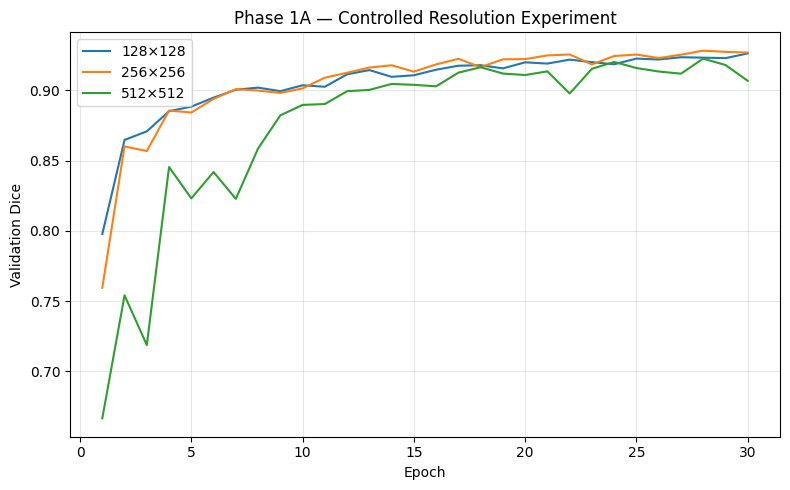

✓ Saved: /content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1A_resolution/plots/validation_dice_by_resolution.png


In [ ]:
# ================================================================
# PHASE 1A — CELL 40
# VALIDATION DICE CURVES
# ================================================================

plt.figure(
    figsize=(8, 5)
)

for resolution in [
    128,
    256,
    512
]:

    history_df = pd.read_csv(
        P1A_HISTORY_DIR
        / f"history_{resolution}.csv"
    )

    plt.plot(
        history_df["epoch"],
        history_df[
            "val_dice_coefficient"
        ],
        label=f"{resolution}×{resolution}"
    )


plt.xlabel("Epoch")
plt.ylabel("Validation Dice")
plt.title(
    "Phase 1A — Controlled Resolution Experiment"
)
plt.legend()
plt.grid(
    alpha=0.3
)
plt.tight_layout()

plot_path = (
    P1A_PLOT_DIR
    / "validation_dice_by_resolution.png"
)

plt.savefig(
    plot_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    "✓ Saved:",
    plot_path
)

In [ ]:
# ================================================================
# PHASE 1A — CELL 41
# FINALIZE RESOLUTION SELECTION
# ================================================================

SELECTED_RESOLUTION = 256

phase1a_final_decision = {

    "phase": "Phase 1A — Controlled Resolution Experiment",

    "status": "COMPLETED",

    "selected_resolution": SELECTED_RESOLUTION,

    "selection_scope":
        "Working input resolution for subsequent Phase 1 experiments",

    "architecture_used":
        "Baseline U-Net",

    "parameter_count":
        int(BASELINE_PARAMETER_COUNT),

    "resolutions_compared":
        [128, 256, 512],

    "selection_dataset":
        "Validation set only",

    "test_set_used":
        False,

    "selected_256_validation_results": {

        "overall_dice":
            float(
                resolution_comparison.loc[
                    resolution_comparison["resolution"] == 256,
                    "overall_dice"
                ].iloc[0]
            ),

        "ED_dice":
            float(
                resolution_comparison.loc[
                    resolution_comparison["resolution"] == 256,
                    "ED_dice"
                ].iloc[0]
            ),

        "ES_dice":
            float(
                resolution_comparison.loc[
                    resolution_comparison["resolution"] == 256,
                    "ES_dice"
                ].iloc[0]
            ),

        "overall_iou":
            float(
                resolution_comparison.loc[
                    resolution_comparison["resolution"] == 256,
                    "overall_iou"
                ].iloc[0]
            ),

        "ED_area_MAE_pct":
            float(
                resolution_comparison.loc[
                    resolution_comparison["resolution"] == 256,
                    "ED_area_MAE_pct"
                ].iloc[0]
            ),

        "ES_area_MAE_pct":
            float(
                resolution_comparison.loc[
                    resolution_comparison["resolution"] == 256,
                    "ES_area_MAE_pct"
                ].iloc[0]
            ),

        "overall_area_MAE_pct":
            float(
                resolution_comparison.loc[
                    resolution_comparison["resolution"] == 256,
                    "overall_area_MAE_pct"
                ].iloc[0]
            )
    },

    "reason_for_selection": (
        "256x256 achieved the highest overall validation Dice and IoU "
        "and the lowest overall LV area MAE among the tested resolutions. "
        "It also produced lower ES area error than 128x128 and 512x512, "
        "while requiring substantially less training time than 512x512."
    ),

    "important_note": (
        "Only the input resolution is selected at this stage. "
        "The current 1,940,817-parameter U-Net is a baseline model and "
        "is NOT the final segmentation model. Hyperparameters, model "
        "capacity, and loss function will be investigated in subsequent "
        "Phase 1 experiments."
    ),

    "next_phase":
        "Phase 1B — Controlled Hyperparameter Experiments"
}


decision_path = (
    P1A_CONFIG_DIR
    / "phase1A_final_resolution_decision.json"
)


with open(
    decision_path,
    "w"
) as f:

    json.dump(
        phase1a_final_decision,
        f,
        indent=2
    )


print("=" * 70)
print("PHASE 1A COMPLETED")
print("=" * 70)

print("\nSelected working resolution:")
print(f"{SELECTED_RESOLUTION}×{SELECTED_RESOLUTION}")

print("\nFinal segmentation model frozen?")
print("NO")

print("\nWhat is frozen?")
print("Input resolution = 256×256")

print("\nNext:")
print("Phase 1B — Controlled Hyperparameter Experiments")

print("\nDecision saved to:")
print(decision_path)

print("\n✓ Phase 1A officially closed.")

PHASE 1A COMPLETED

Selected working resolution:
256×256

Final segmentation model frozen?
NO

What is frozen?
Input resolution = 256×256

Next:
Phase 1B — Controlled Hyperparameter Experiments

Decision saved to:
/content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1A_resolution/configs/phase1A_final_resolution_decision.json

✓ Phase 1A officially closed.
